In [1]:
#import libraries
import pandas as pd
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Load dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!ls /content/drive/

MyDrive


In [4]:
file_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/data/raw/Student Depression Dataset.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
#dropping unwanted columns
columns_to_drop = [
'id', 'City','Profession', 'Work Pressure', 'Job Satisfaction','Degree', 'Financial Stress', 'Study Satisfaction','Academic Pressure','Sleep Duration'
]
existing_columns_to_drop = [col for col in columns_to_drop if col in df.columns]
if existing_columns_to_drop:
    df.drop(columns=existing_columns_to_drop, inplace=True)
    print(f"Successfully removed columns: {existing_columns_to_drop}")
else:
    print("No specified columns found to drop.")


Successfully removed columns: ['id', 'City', 'Profession', 'Work Pressure', 'Job Satisfaction', 'Degree', 'Financial Stress', 'Study Satisfaction', 'Academic Pressure', 'Sleep Duration']


In [6]:
#renaming columns
df = df.rename(columns={"Dietary Habits":"Dietary_Habits", "Work/Study Hours": "Study_Hours", "Have you ever had suicidal thoughts ?":"Suicidal_Thoughts", "Family History of Mental Illness":"Family_History"})

In [7]:
#print first 5 rows of the dataset after removing unwanted columns
df.head()

,Gender,Age,CGPA,Dietary_Habits,Suicidal_Thoughts,Study_Hours,Family_History,Depression
0,Male,33,8.97,Healthy,Yes,3,No,1
1,Female,24,5.90,Moderate,No,3,Yes,0
2,Male,31,7.03,Healthy,No,9,Yes,0
3,Female,28,5.59,Moderate,Yes,4,Yes,1
4,Female,25,8.13,Moderate,Yes,1,No,0


In [8]:
#print last 5 rows of the dataset
df.tail()

,Gender,Age,CGPA,Dietary_Habits,Suicidal_Thoughts,Study_Hours,Family_History,Depression
27896,Female,27,5.75,Unhealthy,Yes,7,Yes,0
27897,Male,27,9.40,Healthy,No,0,Yes,0
27898,Male,31,6.61,Unhealthy,No,12,No,0
27899,Female,18,6.88,Healthy,Yes,10,No,1
27900,Male,27,9.24,Healthy,Yes,2,Yes,1


In [9]:
#removing duplicates
duplicates_before = df.duplicated().sum()
print(f"Found {duplicates_before} duplicate rows before cleaning.")

df.drop_duplicates(inplace=True)

duplicates_after = df.duplicated().sum()
print(f"Removed duplicates. There are now {duplicates_after} duplicate rows.")
print(f"The dataset now has {len(df)} unique rows.")

Found 616 duplicate rows before cleaning.
Removed duplicates. There are now 0 duplicate rows.
The dataset now has 27285 unique rows.


In [10]:
## Check the data types of each column in the dataframe
df.dtypes

,0
Gender,object
Age,int64
CGPA,float64
Dietary_Habits,object
Suicidal_Thoughts,object
Study_Hours,int64
Family_History,object
Depression,int64


In [11]:
#identifying missing values
print(df.isnull().sum())

Gender               0
Age                  0
CGPA                 0
Dietary_Habits       0
Suicidal_Thoughts    0
Study_Hours          0
Family_History       0
Depression           0
dtype: int64


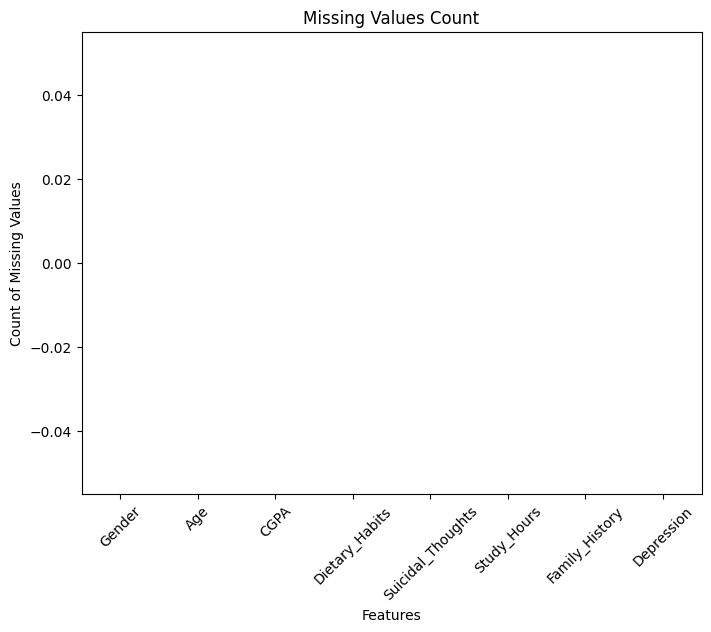

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102082_visualization_missing_values_count.png


In [12]:
#visualization for missing values count
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
df.isnull().sum().plot(kind='bar', color='purple')
plt.title("Missing Values Count")
plt.xlabel("Features")
plt.ylabel("Count of Missing Values")
plt.xticks(rotation=45)

# Save path
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102082_visualization_missing_values_count.png"

# Save and show
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved and displayed: {save_path}")


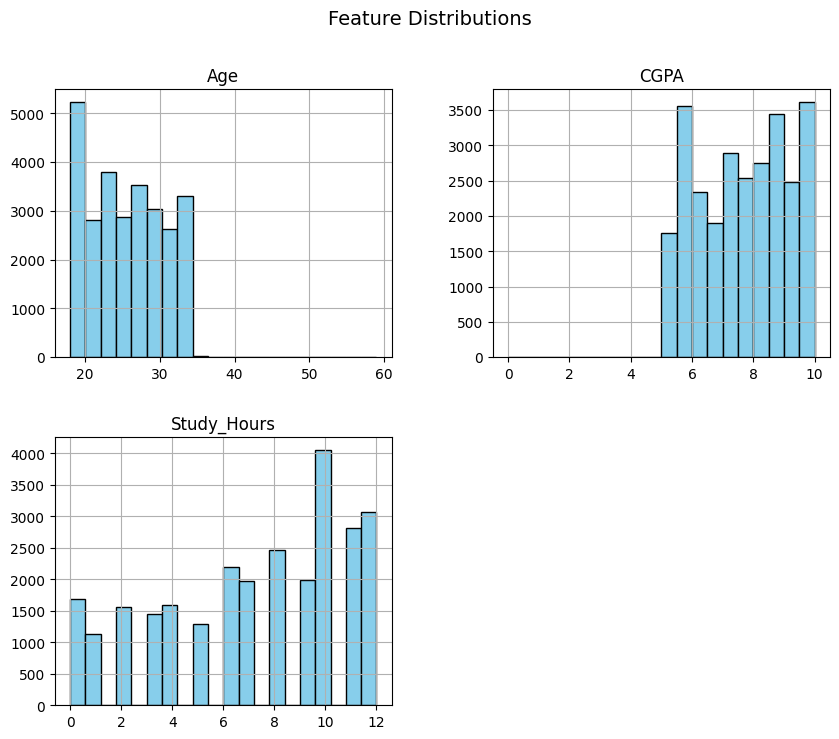

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102082_visualization_cleaning_data_feature_distributions.png


In [13]:
# Exclude the target column for feature histograms
df.drop('Depression', axis=1).hist(bins=20, figsize=(10,8), color="skyblue", edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=14)

# Save path
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102082_visualization_cleaning_data_feature_distributions.png"

# Save and show
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved and displayed: {save_path}")

In [14]:
output_path = '/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/cleaned_student_depression_data.csv'
df.to_csv(output_path, index=False)
print(f"\nCleaned dataset with {len(df)} rows saved successfully at: {output_path}")


Cleaned dataset with 27285 rows saved successfully at: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/cleaned_student_depression_data.csv
